# 09 Look inside the clusters

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
sys.path.append("..")          # cf_common.py is in the folder above
from cf_common import load_data

data = load_data()
names = pd.read_csv("cache/tracks.csv")["track"].to_numpy()       # column -> "title — artist"
Path("figures").mkdir(exist_ok=True)

# users whose tracks are all outside the vocabulary have an empty vector; they all land in one cluster
empty = data.ratings.getnnz(axis=1) == 0


def cluster_color(cluster):
    """tab20 colours, the dark ones first so that clusters next to each other look different."""
    return plt.get_cmap("tab20")((2 * cluster) % 20 + (2 * cluster) // 20)


# has_artist[user, artist] is True if the user has a track by that artist
artist_of_track, artist_names = pd.factorize(pd.Series(names).str.rsplit(" — ", n=1).str[-1])
track_to_artist = sp.csr_matrix((np.ones(len(names)), (np.arange(len(names)), artist_of_track)))
has_artist = ((data.ratings > 0).astype(np.float32) @ track_to_artist) > 0          # users x artists

476,451 users, 120,650 items, 10,000 users are evaluated


## Figure 1: labelled CURE map and what the clusters contain (k = 10)
All users in 2-D (PCA of the 8-dim embedding, 20,000 random users), coloured by CURE cluster for k = 10, with
the most common artists of every cluster. Overlap in 2-D doesn't have to mean overlap in 8-D.

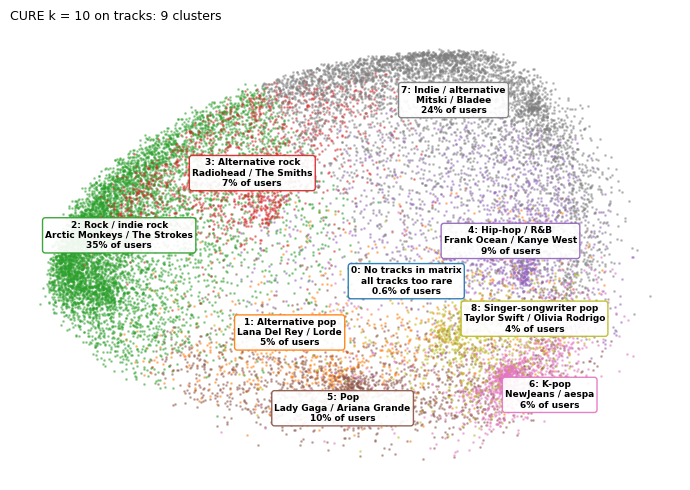

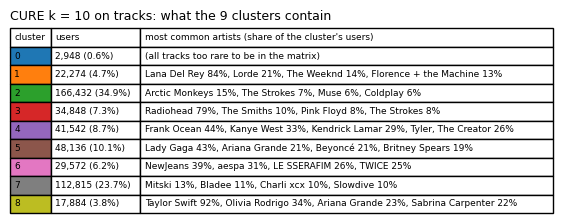

,cluster,users,most common artists (share of the cluster's users)
0,0,"2,948 (0.6%)",(all tracks too rare to be in the matrix)
1,1,"22,274 (4.7%)","Lana Del Rey 84%, Lorde 21%, The Weeknd 14%, F..."
2,2,"166,432 (34.9%)","Arctic Monkeys 15%, The Strokes 7%, Muse 6%, C..."
3,3,"34,848 (7.3%)","Radiohead 79%, The Smiths 10%, Pink Floyd 8%, ..."
4,4,"41,542 (8.7%)","Frank Ocean 44%, Kanye West 33%, Kendrick Lama..."
5,5,"48,136 (10.1%)","Lady Gaga 43%, Ariana Grande 21%, Beyoncé 21%,..."
6,6,"29,572 (6.2%)","NewJeans 39%, aespa 31%, LE SSERAFIM 26%, TWIC..."
7,7,"112,815 (23.7%)","Mitski 13%, Bladee 11%, Charli xcx 10%, Slowdi..."
8,8,"17,884 (3.8%)","Taylor Swift 92%, Olivia Rodrigo 34%, Ariana G..."


In [2]:
shown = np.random.default_rng(1).choice(data.n_users, size=20_000, replace=False)
pca = PCA(n_components=2).fit(data.embedding[shown])
xy = pca.transform(data.embedding[shown])

labels_map = np.load("cache/cure_labels.npz")["k10"]
clusters_map = np.unique(labels_map)

# genre names picked by hand from the most common artists (only right for seed 579)
GENRES = {0: "No tracks in matrix", 1: "Alternative pop", 2: "Rock / indie rock", 3: "Alternative rock",
          4: "Hip-hop / R&B", 5: "Pop", 6: "K-pop", 7: "Indie / alternative", 8: "Singer-songwriter pop"}


def plot_labelled_map(labels_k, genres, offsets, title, filename):
    """Users in 2-D coloured by cluster, with a box in the middle of every cluster: genre, two most common
    artists and size. offsets moves some boxes (in points) so they don't overlap."""
    fig, ax = plt.subplots(figsize=(7, 5))
    for cluster in np.unique(labels_k):
        members = np.flatnonzero(labels_k == cluster)
        mine = labels_k[shown] == cluster
        ax.scatter(xy[mine, 0], xy[mine, 1], s=1, alpha=0.4, color=cluster_color(cluster), rasterized=True)
        if empty[members].all():
            artists = "all tracks too rare"
        else:
            share = np.asarray(has_artist[members].sum(axis=0)).ravel() / len(members)
            artists = " / ".join(artist_names[i] for i in np.argsort(-share)[:2])
        percent = 100 * len(members) / data.n_users
        ax.annotate(f"{cluster}: {genres.get(cluster, '?')}\n{artists}\n{percent:.{0 if percent >= 1 else 1}f}% of users",
                    np.median(xy[mine], axis=0), xytext=offsets.get(cluster, (0, 0)), textcoords="offset points",
                    ha="center", va="center", fontsize=6.5, fontweight="bold", linespacing=1.2,
                    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor=cluster_color(cluster), alpha=0.92))
    ax.set_title(title, loc="left", fontsize=9)
    ax.axis("off")
    fig.tight_layout()
    fig.savefig(filename, dpi=300, bbox_inches="tight")      # PDF: text and boxes stay sharp, the dots are an image
    plt.show()


# move the pop labels apart, they overlap otherwise
plot_labelled_map(labels_map, GENRES, {1: (-45, 13), 8: (48, 16), 5: (-13, -19), 6: (29, -16)},
                  f"CURE k = 10 on tracks: {len(clusters_map)} clusters", "figures/cluster_map_k10_labelled.pdf")

# what every cluster contains: size and the four most common artists (share of the cluster's users)
rows = []
for cluster in clusters_map:
    members = np.flatnonzero(labels_map == cluster)
    if empty[members].all():
        top = "(all tracks too rare to be in the matrix)"
    else:
        share = np.asarray(has_artist[members].sum(axis=0)).ravel() / len(members)
        top = ", ".join(f"{artist_names[i]} {100 * share[i]:.0f}%" for i in np.argsort(-share)[:4])
    rows.append({"cluster": cluster, "users": f"{len(members):,} ({100 * len(members) / data.n_users:.1f}%)",
                 "most common artists (share of the cluster's users)": top})
contents = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 0.24 * (len(contents) + 1)))
ax.axis("off")
table = ax.table(cellText=contents.values, colLabels=contents.columns, cellLoc="left", colLoc="left",
                 colWidths=[0.075, 0.165, 0.76], bbox=[0, 0, 1, 1])
table.auto_set_font_size(False)
table.set_fontsize(6.5)
for (row, col), cell in table.get_celld().items():
    cell.PAD = [0.1, 0.05, 0.012][col]          # space before the text, as a share of the column width
for row, cluster in enumerate(contents["cluster"], start=1):
    table[row, 0].set_facecolor(cluster_color(cluster))
ax.set_title(f"CURE k = 10 on tracks: what the {len(clusters_map)} clusters contain", loc="left", fontsize=9)
fig.savefig("figures/cluster_contents_k10.pdf", bbox_inches="tight")
plt.show()
contents

## Figure 2: the same map for k-means (k = 10)
Same settings as `03_kmeans`. Its labels are not saved, so it is fitted again here (a few seconds).
Same 2-D projection and users as Figure 1.

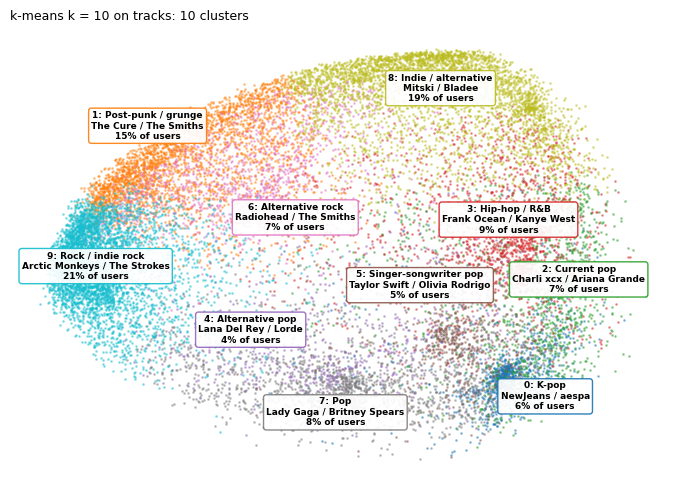

In [3]:
from sklearn.cluster import KMeans

kmeans_labels = KMeans(n_clusters=10, n_init=3, random_state=579).fit_predict(data.embedding)

# genre names picked by hand from the most common artists (only right for seed 579)
KMEANS_GENRES = {0: "K-pop", 1: "Post-punk / grunge", 2: "Current pop", 3: "Hip-hop / R&B", 4: "Alternative pop",
                 5: "Singer-songwriter pop", 6: "Alternative rock", 7: "Pop", 8: "Indie / alternative",
                 9: "Rock / indie rock"}
plot_labelled_map(kmeans_labels, KMEANS_GENRES, {1: (-29, 29), 6: (32, -26), 4: (-64, 16), 5: (-26, 35),
                                                 7: (0, -19), 0: (29, -16), 2: (29, 10), 3: (0, 13)},
                  "k-means k = 10 on tracks: 10 clusters", "figures/kmeans_map_k10_labelled.pdf")

## Figure 3: multi-view clusters (concatenated embedding)
Labels from `08_multiview` (`cache/multiview_labels.npz`). The dots are in the same places as in
Figures 1 and 2 (the tracks embedding), only the colours are the multi-view clusters. The genre names come from
the tracks of each cluster's users.

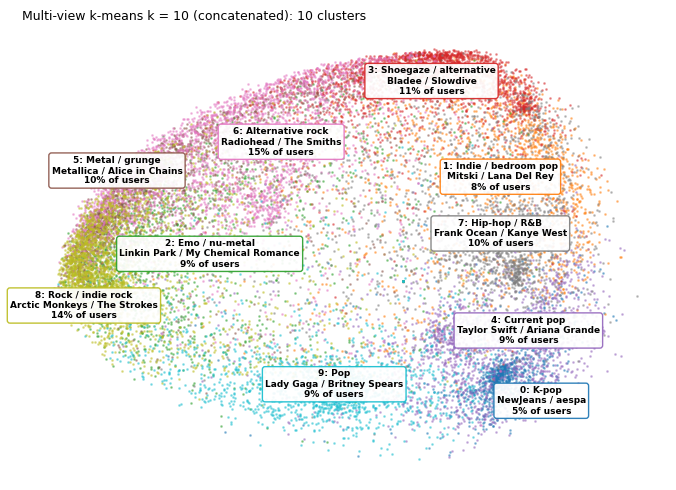

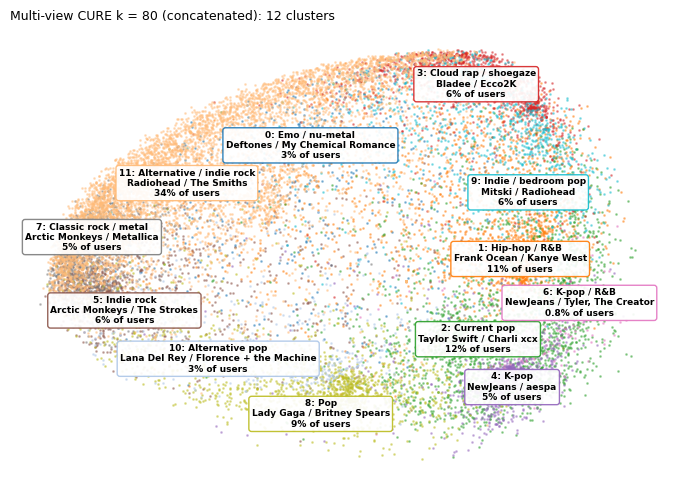

In [4]:
multiview_labels = np.load("cache/multiview_labels.npz")

# genre names picked by hand from the most common artists (only right for seed 579)
MV_KMEANS_GENRES = {0: "K-pop", 1: "Indie / bedroom pop", 2: "Emo / nu-metal", 3: "Shoegaze / alternative",
                    4: "Current pop", 5: "Metal / grunge", 6: "Alternative rock", 7: "Hip-hop / R&B",
                    8: "Rock / indie rock", 9: "Pop"}
plot_labelled_map(multiview_labels["kmeans_concatenated_k10"], MV_KMEANS_GENRES,
                  {5: (-26, 19), 6: (35, 19), 2: (29, 0), 8: (-19, -26), 4: (29, 10), 0: (29, -19)},
                  "Multi-view k-means k = 10 (concatenated): 10 clusters", "figures/multiview_kmeans_map_k10_labelled.pdf")

MV_CURE_GENRES = {0: "Emo / nu-metal", 1: "Hip-hop / R&B", 2: "Current pop", 3: "Cloud rap / shoegaze", 4: "K-pop",
                  5: "Indie rock", 6: "K-pop / R&B", 7: "Classic rock / metal", 8: "Pop", 9: "Indie / bedroom pop",
                  10: "Alternative pop", 11: "Alternative / indie rock"}
plot_labelled_map(multiview_labels["cure_concatenated_k80"], MV_CURE_GENRES,
                  {1: (19, -26), 10: (-30, -8), 0: (0, 19), 8: (0, -22), 9: (26, -45), 6: (26, 22), 7: (0, 16),
                   5: (6, -16), 2: (-19, -6), 4: (5, -8)},
                  "Multi-view CURE k = 80 (concatenated): 12 clusters", "figures/multiview_cure_map_k80_labelled.pdf")